# <font color="red">Read data</font>

In [70]:
import pandas as pd

data = pd.read_excel("data.xlsx")

data = data[data.Country != "Israel"]



# <font color="red">Explore et analyse data</font>

## <font color="green">general data</font>

In [71]:
# # shape, size
# print("shape:", data.shape)

# # columns
# print(data.columns)

# # types
# print(data.dtypes)

# # info
# print(data.info())

# # duplucated
# print(data.duplicated())



## <font color="green">clean data</font>

In [72]:
import datetime as dt
def clean_na_neg():
    global data
    
    data = data.dropna(subset=["CustomerID"])
    
    data = data[data.Quantity > 0]
    # data["Description"] = data["Description"].fillna("No desc")
    
    print(data.shape) 
    
def convert_types():
    data["CustomerID"]= data["CustomerID"].astype("int64")
    data["InvoiceNo"] = data["InvoiceNo"].astype("str")
    data["StockCode"] = data["StockCode"].astype("str")
    data["Description"] = data["Description"].astype("str")
    data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
    
clean_na_neg()
convert_types()

# print(data.info())  
    
    

(397676, 8)


## <font color="green">RFM</font>

In [73]:
def get_recency():
    # connait le fédality du clients 
    def calculate_date_diff():
        last_date_sale = data.InvoiceDate.max() + dt.timedelta(days=1)
        last_sales_by_client  = data.groupby("CustomerID")["InvoiceDate"].max()
        return (last_date_sale - last_sales_by_client).dt.days


    recency = calculate_date_diff()

    return recency 
    

def get_frequence():
    # connait le nomber de transaction fait par clients
    counts = data["CustomerID"].value_counts()
    return counts
    
def get_montary():
    # connait combien du argent gaspillé 
    max_sales = data.assign(total= data["Quantity"]* data["UnitPrice"]).groupby("CustomerID")["total"].sum()
    return max_sales

recency, frequence, montary = get_recency(), get_frequence(), get_montary()


ids = data.CustomerID.unique()

clients_rfm = {
    "ClientId": [],
    "recency": [],
    "frequence": [],
    "montary": []
}
for i in ids:
    clients_rfm["ClientId"].append(i)
    clients_rfm["recency"].append(recency[i])
    clients_rfm["frequence"].append(frequence[i])
    clients_rfm["montary"].append(montary[i])
    
df_clients_rfm = pd.DataFrame(clients_rfm)    
df_clients_rfm.head()


    

,ClientId,recency,frequence,montary
0,17850,372,297,5391.21
1,13047,32,172,3237.54
2,12583,3,247,7281.38
3,13748,96,28,948.25
4,15100,334,3,876.00


In [74]:
df_clients_rfm.shape

(4336, 4)

## <font color="green">preparation des variables pour claustring</font>

In [75]:
import numpy as np

def to_log1p():
    df_clients_rfm["recency"] = np.log1p(df_clients_rfm["recency"])
    df_clients_rfm["frequence"] = np.log1p(df_clients_rfm["frequence"])
    df_clients_rfm["montary"] = np.log1p(df_clients_rfm["montary"])

to_log1p()


## <font color="green">charts</font>

In [76]:
# import matplotlib.pyplot as plt

# def get_boxplot():
#     recency = df_clients_rfm["recency"]
#     frequence = df_clients_rfm["frequence"]
#     montary = df_clients_rfm["montary"]   
     
#     fig, axes = plt.subplots(1, 3, figsize=(12, 4))

#     axes[0].boxplot(recency)
#     axes[0].set_title("Recency")

#     axes[1].boxplot(frequence)
#     axes[1].set_title("Frequency")

#     axes[2].boxplot(montary)
#     axes[2].set_title("Monetary")

#     plt.tight_layout()
#     plt.show()
    
# get_boxplot()    
    


In [77]:
# def get_hists(bins = 30):
#     recency = df_clients_rfm["recency"]
#     frequence = df_clients_rfm["frequence"]
#     montary = df_clients_rfm["montary"]  
    
#     fig, axes = plt.subplots(1, 3, figsize=(12, 4))

#     axes[0].hist(recency, bins= bins)
#     axes[0].set_title("Recency")

#     axes[1].hist(frequence, bins= bins)
#     axes[1].set_title("Frequency")

#     axes[2].hist(montary, bins= bins)
#     axes[2].set_title("Monetary")

#     plt.tight_layout()
#     plt.show()
    
# get_hists()   

## <font color="green">scaler</font>

In [92]:
from sklearn.preprocessing import StandardScaler

features = ["frequence", "recency", "montary"]
scaler = StandardScaler()

X = scaler.fit_transform(df_clients_rfm[features])


df_clients_rfm["recency"]= X[:, 0]
df_clients_rfm["frequence"] = X[:, 1]
df_clients_rfm["montary"] = X[:, 2]


## <font color="green">visualisation elbow & silhouette</font>

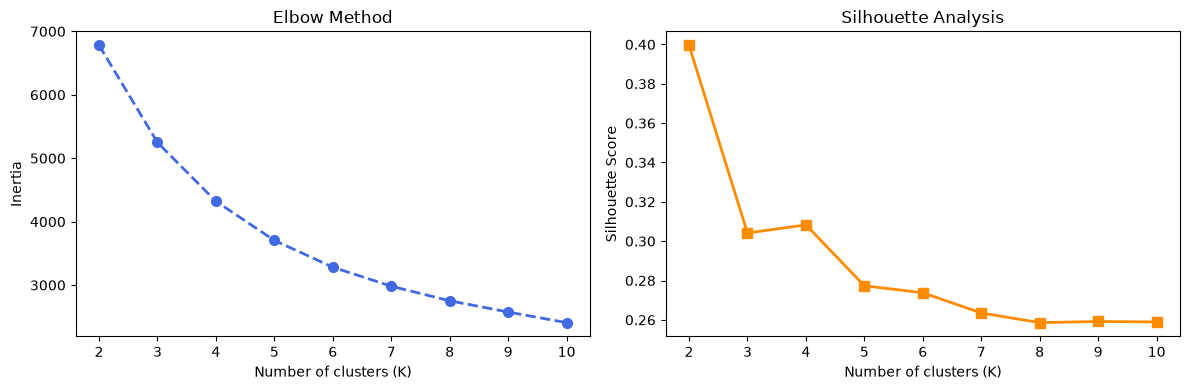

In [79]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt


def kmean():
    inertias = []
    sil_scores = []

    # Elbow can use K=1, but Silhouette needs K >= 2
    ks = range(2, 11)

    for k in ks:
        k_means = KMeans(
            n_clusters=k,
            init="k-means++",
            random_state=42,
            n_init=10
        )
        # fit(): set the centroids
        # predict(): predict the cluster label for each point in X
        labels = k_means.fit_predict(X) 

        # Inertia
        inertias.append(k_means.inertia_)

        # Silhouette Score
        # check if point existe in right cluster
        score = silhouette_score(X, labels) 
        sil_scores.append(score)
       

    # Create plots
    visualize_elbow_silhouette(ks, inertias, sil_scores)

def visualize_elbow_silhouette(ks, inertias, sil_scores):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        # Elbow
        axes[0].plot(
            ks,
            inertias,
            color="royalblue",
            marker="o",
            linestyle="--",
            linewidth=2,
            markersize=7
        )

        axes[0].set_xlabel("Number of clusters (K)")
        axes[0].set_ylabel("Inertia")
        axes[0].set_title("Elbow Method")

        # Silhouette
        axes[1].plot(
            ks,
            sil_scores,
            color="darkorange",
            marker="s",
            linestyle="-",
            linewidth=2,
            markersize=7
        )

        axes[1].set_xlabel("Number of clusters (K)")
        axes[1].set_ylabel("Silhouette Score")
        axes[1].set_title("Silhouette Analysis")

        plt.tight_layout()
        plt.show()


kmean()

## <font color="green">Train model</font>

In [93]:
from sklearn.cluster import KMeans
def trained_k_mean():
    kmean = KMeans(n_clusters=3, init="k-means++", random_state=42, n_init=10)
    kmean = kmean.fit(X)
    return kmean

In [81]:

kmean = trained_k_mean()

In [94]:
df_clients_rfm["cluster"] = kmean.labels_
df_clients_rfm.head()

,ClientId,recency,frequence,montary,cluster,PC1,PC2
0,17850,1.567072,1.560577,1.586758,1,1.127737,2.477087
1,13047,1.132462,-0.248745,1.182453,2,1.536138,0.618171
2,12583,1.420286,-1.823155,1.825062,2,2.902229,-0.398139
3,13748,-0.294917,0.555692,0.209258,1,-0.335319,0.455000
4,15100,-1.878146,1.480411,0.146479,0,-1.810024,0.681872


In [83]:
import numpy as np

def centroids_tabel():
    r = np.expm1(scaler.inverse_transform(kmean.cluster_centers_))
    cend_t= pd.DataFrame(r, index=["cluster 1", "cluster 2", "cluster 3"], columns= features).round(2)
    return cend_t
        
centroids_tabel()  

,frequence,recency,montary
cluster 1,11.45,132.41,230.57
cluster 2,50.13,41.94,816.71
cluster 3,183.92,9.37,3385.18


In [84]:
 df_clients_rfm.head()

,ClientId,recency,frequence,montary,cluster
0,17850,5.921578,5.697093,8.592711,1
1,13047,3.496508,5.153292,8.082878,2
2,12583,1.386294,5.513429,8.893213,2
3,13748,4.574711,3.367296,6.855672,1
4,15100,5.814131,1.386294,6.776507,0


In [85]:

def clusters_table():

    cluster_groups = df_clients_rfm.groupby("cluster")

    data = {
        "Count": cluster_groups.size(),

        "Mean Recency": cluster_groups["recency"].mean(),

        "Mean Frequence": cluster_groups["frequence"].mean(),

        "Mean Monetary": cluster_groups["montary"].mean(),
        
        "Distribution": (cluster_groups["montary"].sum() /100 )* df_clients_rfm["montary"].sum(),

        "Total Monetary": cluster_groups["montary"].sum()
    }

    df = pd.DataFrame(data)

    df.index = [f"Cluster {i + 1}" for i in df.index]

    return df

clusters_table()



,Count,Mean Recency,Mean Frequence,Mean Monetary,Distribution,Total Monetary
Cluster 1,1509,4.892564,2.523179,5.445057,2.348468e+06,8216.590844
Cluster 2,1846,3.759227,3.938445,6.711546,3.541174e+06,12389.513837
Cluster 3,981,2.328298,5.222002,8.130400,2.279680e+06,7975.922197


## <font color="green">PCA</font>

In [86]:
from sklearn.decomposition import PCA


pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

df_clients_rfm["PC1"] = X_pca[:, 0]
df_clients_rfm["PC2"] = X_pca[:, 1]

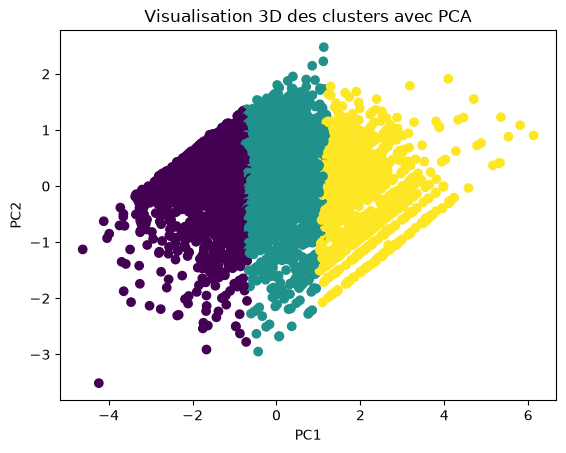

In [87]:
import matplotlib.pyplot as plt

plt.scatter(
    df_clients_rfm["PC1"],
    df_clients_rfm["PC2"],
    c=df_clients_rfm["cluster"],
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("Visualisation 3D des clusters avec PCA")

plt.show()

## <font color="green">Supervisé</font>

In [95]:
df_clients_rfm.head()

,ClientId,recency,frequence,montary,cluster,PC1,PC2
0,17850,1.567072,1.560577,1.586758,1,1.127737,2.477087
1,13047,1.132462,-0.248745,1.182453,2,1.536138,0.618171
2,12583,1.420286,-1.823155,1.825062,2,2.902229,-0.398139
3,13748,-0.294917,0.555692,0.209258,1,-0.335319,0.455000
4,15100,-1.878146,1.480411,0.146479,0,-1.810024,0.681872


In [103]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
import joblib

features = df_clients_rfm.drop(columns=["cluster", "PC1", "PC2", "ClientId"])
target = df_clients_rfm.cluster

X_train, X_test, y_train, y_test= train_test_split(features, target, test_size=0.2, random_state=42)

def saveModel(file_name, model):
    joblib.dump(model, open(f"models/{file_name}", 'wb'))
    
def loadmodel(file_name):
    model = joblib.load(open(f"models/{file_name}", "rb"))
    return model

def train_validate():
    model = RandomForestClassifier()
    kfold = StratifiedKFold(n_splits=2, random_state=42, shuffle=True)
    def validate():
        scoring = {
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro"
        }
    
        cv_results = cross_validate(
            model,
            X_train,
            y_train,
            cv=kfold,
            scoring=scoring
        )
        
        print("Accuracy :", cv_results["test_accuracy"])
        print("Precision:", cv_results["test_precision"])
        print("Recall   :", cv_results["test_recall"])
        print("F1-score :", cv_results["test_f1"])
    validate()    
    model = model.fit(X_train, y_train)
    return model

model = train_validate()


Accuracy : [0.97404844 0.96309112]
Precision: [0.97269946 0.96560461]
Recall   : [0.97389107 0.96030545]
F1-score : [0.97328474 0.96281292]


In [104]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].